# Exploration des structures BSV

Objectif : contrôler la qualité des tables `bsv_bulletins.csv` et `bsv_observations.csv`, produire des statistiques exploratoires, puis identifier les bulletins avec ou sans bioagresseurs d'intérêt pour la tomate.

Analyse détaillée des observations tomate — bioagresseurs, chronologie, météo associée, niveau de risque, indicateurs quantitatifs, tableau de synthèse exportable.


## 0. Préparation

Le notebook est conçu pour être lancé depuis le dossier `notebooks/` ou depuis la racine du projet.

In [1]:
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 160)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

BULLETINS_PATH = PROJECT_ROOT / "data" / "processed" / "bsv_bulletins.csv"
OBSERVATIONS_PATH = PROJECT_ROOT / "data" / "processed" / "bsv_observations.csv"
REFERENTIEL_CNN_PATH = PROJECT_ROOT / "data" / "raw" / "referentiel_cnn_bsv.csv"

def read_csv_auto(path: Path, **kwargs) -> pd.DataFrame:
    """Read CSV files produced or supplied with mixed encodings/separators."""
    last_error = None
    for encoding in ("utf-8-sig", "cp1252", "latin-1"):
        try:
            return pd.read_csv(path, encoding=encoding, sep=None, engine="python", **kwargs)
        except UnicodeDecodeError as exc:
            last_error = exc
    raise last_error

def normalize_text(value) -> str:
    if pd.isna(value):
        return ""
    value = str(value).lower()
    value = unicodedata.normalize("NFKD", value)
    value = "".join(char for char in value if not unicodedata.combining(char))
    value = re.sub(r"[^a-z0-9]+", " ", value)
    return re.sub(r"\s+", " ", value).strip()

def show_bar(series: pd.Series, title: str, xlabel: str = ""):
    ax = series.plot(kind="bar", figsize=(10, 4))
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("Nombre")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

## 1. Chargement des données

In [2]:
bulletins = read_csv_auto(BULLETINS_PATH)
observations = read_csv_auto(OBSERVATIONS_PATH)

bulletins["date_bulletin"] = pd.to_datetime(bulletins["date_bulletin"], errors="coerce")

observations_enrichies = observations.merge(
    bulletins[["bulletin_id", "region", "date_bulletin", "periode_prevision_meteo"]],
    on="bulletin_id",
    how="left",
)

print(f"Bulletins : {len(bulletins):,}")
print(f"Observations : {len(observations):,}")
display(bulletins.head())
display(observations_enrichies.head())

Bulletins : 157
Observations : 3,272


,bulletin_id,region,date_bulletin,template_id,nature_meteo,meteo_extraction_status,meteo_extraction_method,meteo_extraction_score,periode_prevision_meteo,prevision_meteo
0,grandest_2023_bsv01,Grand Est,2023-04-19,grand_est_standard,prevision,image_seule,general:weather_source,11,20/04/2023-26/04/2023,"(Source : Météo France, commune de Innenheim, 19/04/2023 à 14h30. Retrouvez les données météo actualisées ici)  Oignon et Pomme de terre (Source : Météo Fr..."
1,grandest_2023_bsv02,Grand Est,2023-04-26,grand_est_standard,prevision,image_seule,general:weather_source,11,27/04/2023-03/05/2023,"(Source : Météo France, commune de Innenheim, 19/04/2023 à 11h10. Retrouvez les données météo actualisées ici)  Oignon et Pomme de terre (Source : Météo Fr..."
2,grandest_2023_bsv03,Grand Est,2023-05-04,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,15,05/05/2023-11/05/2023,"• Laitue, solanacées et cucurbitacées sous abri (Source : Météo France, commune de Nancy, 04/05/2023 à 10h49. Retrouvez les données météo actualisées ici)"
3,grandest_2023_bsv04,Grand Est,2023-05-11,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,12,12/05/2023-18/05/2023,"(Source : Météo France, ville de Allibaudières, 11/05/2023 à 13h45. Retrouvez les données météo actualisées ici)"
4,grandest_2023_bsv06,Grand Est,2023-05-24,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,15,25/05/2023-31/05/2023," Laitue, solanacées et cucurbitacées sous abri (Source : Météo France, commune de Lunéville, 24/05/2023 à 9h50. Retrouvez les données météo actualisées ici..."


,bulletin_id,registre,culture,bioagresseur,type,departements,localisations,observation,indicateur_quantitatif,evolution,analyse_risque,niveau_risque_observation,facteurs_favorables,source_information,region,date_bulletin,periode_prevision_meteo
0,grandest_2023_bsv01,observation_parcelle,chou,Chenilles phytophages,ravageur,NaN,NaN,Teigne : 3 adultes de la teigne des crucifères ont été capturées cette semaine sur le piège mis en place. Noctuelle : aucun adulte de noctuelle n’a été capt...,NaN,NaN,"Au vu des conditions climatiques annoncées et du faible nombre d’adultes capturés, il est peu probable d’observer les premières chenilles dès la semaine pro...",fort,NaN,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV01_LEG_GE_S16_2023.txt#L210,Grand Est,2023-04-19,20/04/2023-26/04/2023
1,grandest_2023_bsv01,observation_parcelle,oignon,Thrips,ravageur,NaN,NaN,"Dans la parcelle du réseau, aucun individu n’a été détecté, en revanche sur culture hivernée au stade bulbaison, des adultes, des larves et des dégâts sont ...",NaN,NaN,"Compte tenu des conditions météorologiques, le risque est faible sur les semis de printemps des oignons de garde.",faible,NaN,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV01_LEG_GE_S16_2023.txt#L320,Grand Est,2023-04-19,20/04/2023-26/04/2023
2,grandest_2023_bsv01,observation_parcelle,ombellifères,Mouche de la carotte,ravageur,08;10,NaN,Aucun individu n’a été capturé sur la parcelle de Mussig. Les conditions météorologiques fraiches et pluvieuses ne sont pas propices au vol de la mouche de ...,NaN,NaN,NaN,NaN,NaN,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV01_LEG_GE_S16_2023.txt#L112,Grand Est,2023-04-19,20/04/2023-26/04/2023
3,grandest_2023_bsv01,observation_parcelle,ombellifères,Septoriose,maladie,NaN,NaN,Il n’y a pas d’attaque de septoriose qui a été observée pour l’instant.,NaN,NaN,NaN,NaN,NaN,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV01_LEG_GE_S16_2023.txt#L169,Grand Est,2023-04-19,20/04/2023-26/04/2023
4,grandest_2023_bsv02,observation_parcelle,asperge,Mouche de l’asperge,NaN,NaN,NaN,"Aucun individu n’a été capturé sur les parcelles de Hoerdt et Bennwihr, mais des captures ont été faites sur le site de Rouffach en asperge blanche. Les con...",80%; 50 %,NaN,"Niveau de risque : risque élevé sur le secteur Rouffach. Avec les températures prévues à la hausse, le risque pourrait s’y amplifier. Pour les autres secteu...",fort,"Avec les températures prévues à la hausse, le risque pourrait s’y amplifier",outputs/extracted_text/grandest/legumes_maraichage/2023/BSV02_LEG_GE_S17_2023.txt#L121,Grand Est,2023-04-26,27/04/2023-03/05/2023


## 2. Contrôle qualité

In [3]:
expected_bulletin_cols = [
    "bulletin_id", "region", "date_bulletin", "periode_prevision_meteo", "prevision_meteo"
]
expected_observation_cols = [
    "bulletin_id", "registre", "culture", "bioagresseur", "type", "departements",
    "localisations", "observation", "indicateur_quantitatif", "evolution",
    "analyse_risque", "niveau_risque_observation", "facteurs_favorables", "source_information"
]

quality = pd.DataFrame([
    {
        "table": "bulletins",
        "lignes": len(bulletins),
        "colonnes_manquantes": sorted(set(expected_bulletin_cols) - set(bulletins.columns)),
        "bulletin_id_dupliques": int(bulletins["bulletin_id"].duplicated().sum()),
        "bulletin_id_vides": int(bulletins["bulletin_id"].isna().sum()),
    },
    {
        "table": "observations",
        "lignes": len(observations),
        "colonnes_manquantes": sorted(set(expected_observation_cols) - set(observations.columns)),
        "bulletin_id_dupliques": "n/a",
        "bulletin_id_vides": int(observations["bulletin_id"].isna().sum()),
    },
])

missing_core = observations[["bulletin_id", "culture", "bioagresseur", "observation"]].isna().sum().to_frame("valeurs_vides")
observations_sans_bulletin = observations_enrichies[observations_enrichies["region"].isna()]

display(quality)
display(missing_core)
print(f"Observations sans bulletin correspondant : {len(observations_sans_bulletin):,}")
display(observations_sans_bulletin.head())

,table,lignes,colonnes_manquantes,bulletin_id_dupliques,bulletin_id_vides
0,bulletins,157,[],0,0
1,observations,3272,[],n/a,0


,valeurs_vides
bulletin_id,0
culture,0
bioagresseur,0
observation,0


Observations sans bulletin correspondant : 0


,bulletin_id,registre,culture,bioagresseur,type,departements,localisations,observation,indicateur_quantitatif,evolution,analyse_risque,niveau_risque_observation,facteurs_favorables,source_information,region,date_bulletin,periode_prevision_meteo


## 3. Nombre de bulletins par région

,nb_bulletins
region,
Grand Est,65
Pays de la Loire,92


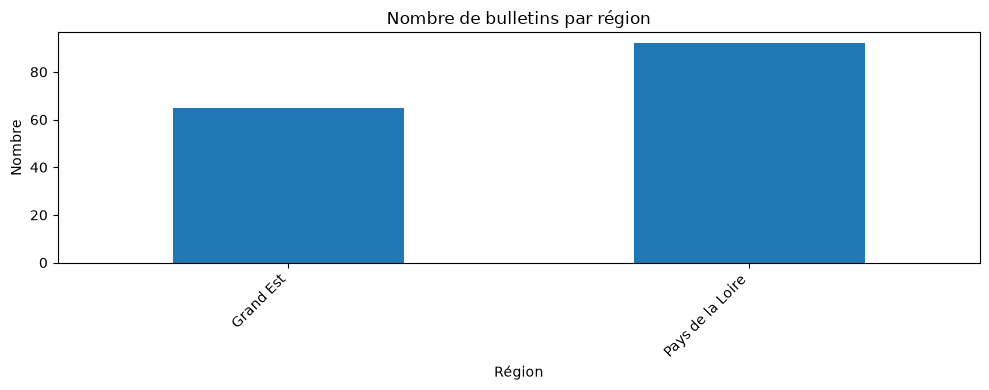

In [4]:
bulletins_par_region = bulletins["region"].value_counts().sort_index()
display(bulletins_par_region.to_frame("nb_bulletins"))
show_bar(bulletins_par_region, "Nombre de bulletins par région", "Région")

## 4. Nombre d'observations par région

,nb_observations
region,
Grand Est,783
Pays de la Loire,2489


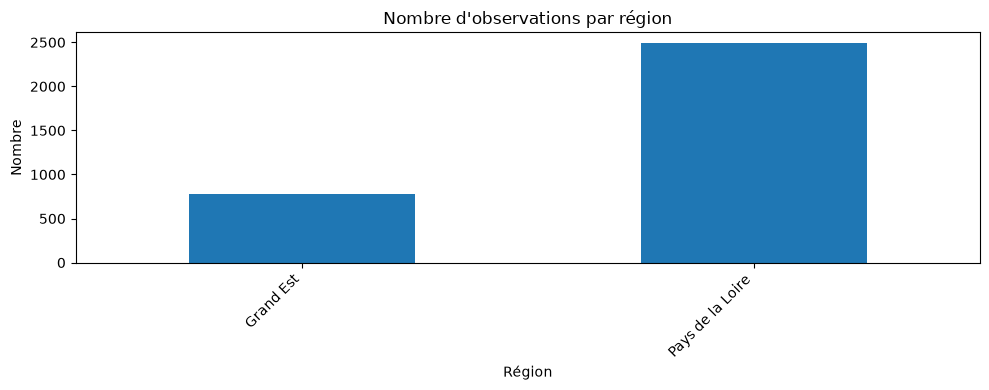

In [5]:
observations_par_region = observations_enrichies["region"].value_counts(dropna=False).sort_index()
display(observations_par_region.to_frame("nb_observations"))
show_bar(observations_par_region, "Nombre d'observations par région", "Région")

## 5. Bioagresseurs les plus fréquents

,nb_observations
bioagresseur,
Mildiou,357
Pucerons,335
Thrips,195
Puceron,169
Oïdium,139
Botrytis,135
Septoriose,79
Alternaria,72
Altises,65


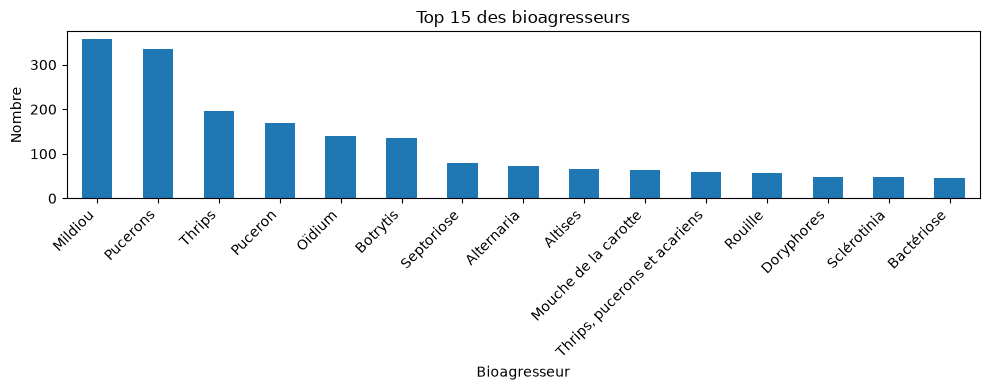

In [6]:
top_bioagresseurs = observations["bioagresseur"].fillna("(vide)").value_counts().head(25)
display(top_bioagresseurs.to_frame("nb_observations"))
show_bar(top_bioagresseurs.head(15), "Top 15 des bioagresseurs", "Bioagresseur")

## 6. Cultures les plus fréquentes

,nb_observations
culture,
chou,319
salade,291
oignon,224
tomate,171
radis,168
pomme de terre,154
mache,154
concombre,154
fraisier,141


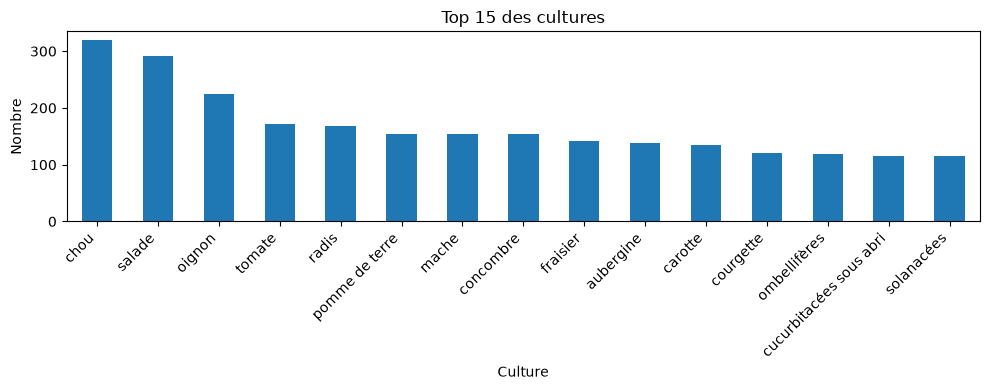

In [7]:
top_cultures = observations["culture"].fillna("(vide)").value_counts().head(25)
display(top_cultures.to_frame("nb_observations"))
show_bar(top_cultures.head(15), "Top 15 des cultures", "Culture")

## 7. Observations concernant tomate general

In [8]:
obs_norm = observations_enrichies.assign(
    culture_norm=observations_enrichies["culture"].map(normalize_text),
    bioagresseur_norm=observations_enrichies["bioagresseur"].map(normalize_text),
    observation_norm=observations_enrichies["observation"].map(normalize_text),
)

tomate_mask = (
    obs_norm["culture_norm"].str.contains(r"\btomates?\b", regex=True, na=False)
    | obs_norm["observation_norm"].str.contains(r"\btomates?\b", regex=True, na=False)
)
obs_tomate = obs_norm[tomate_mask].copy()

print(f"Observations concernant tomate : {len(obs_tomate):,}")
display(obs_tomate[[
    "bulletin_id", "region", "date_bulletin", "culture", "bioagresseur", "type",
    "departements", "observation", "source_information"
]].head(50))

Observations concernant tomate : 325


,bulletin_id,region,date_bulletin,culture,bioagresseur,type,departements,observation,source_information
6,grandest_2023_bsv02,Grand Est,2023-04-26,cucurbitacées sous abri,Pucerons,ravageur,10,"Quelques pucerons observés sur concombre sous abri au nord de Nancy la semaine passée. Cette semaine, aucune observation de puceron sur solanacées et cucurb...",outputs/extracted_text/grandest/legumes_maraichage/2023/BSV02_LEG_GE_S17_2023.txt#L596
11,grandest_2023_bsv02,Grand Est,2023-04-26,solanacées,Pucerons,ravageur,10,"Quelques pucerons observés sur concombre sous abri au nord de Nancy la semaine passée. Cette semaine, aucune observation de puceron sur solanacées et cucurb...",outputs/extracted_text/grandest/legumes_maraichage/2023/BSV02_LEG_GE_S17_2023.txt#L596
14,grandest_2023_bsv03,Grand Est,2023-05-04,cucurbitacées sous abri,Pucerons,ravageur,10,Quelques pucerons observés sur concombre sous abri dans le Toulois. Aucune observation de puceron sur les jeunes solanacées mais de nombreux individus ont é...,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV03_LEG_GE_S18_2023.txt#L599
22,grandest_2023_bsv03,Grand Est,2023-05-04,solanacées,Pucerons,ravageur,10,Quelques pucerons observés sur concombre sous abri dans le Toulois. Aucune observation de puceron sur les jeunes solanacées mais de nombreux individus ont é...,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV03_LEG_GE_S18_2023.txt#L599
25,grandest_2023_bsv04,Grand Est,2023-05-11,cucurbitacées sous abri,Pucerons,ravageur,NaN,"Les premiers pucerons ont été observés sur culture de solanacées, notamment sur culture de tomate et principalement sur culture d’aubergine. Les pressions s...",outputs/extracted_text/grandest/legumes_maraichage/2023/BSV04_LEG_GE_S19_2023.txt#L947
35,grandest_2023_bsv04,Grand Est,2023-05-11,solanacées,Pucerons,ravageur,NaN,"Les premiers pucerons ont été observés sur culture de solanacées, notamment sur culture de tomate et principalement sur culture d’aubergine. Les pressions s...",outputs/extracted_text/grandest/legumes_maraichage/2023/BSV04_LEG_GE_S19_2023.txt#L947
39,grandest_2023_bsv06,Grand Est,2023-05-24,cucurbitacées sous abri,Pucerons,ravageur,NaN,"Secteur de Pont-à-Mousson, début de pression en pucerons verts sur tomate (présence assez faible) au voisinage d’une culture de fraise très atteinte. Pressi...",outputs/extracted_text/grandest/legumes_maraichage/2023/BSV06_LEG_GE_S21_2023.txt#L1090
49,grandest_2023_bsv06,Grand Est,2023-05-24,solanacées,Pucerons,ravageur,NaN,"Secteur de Pont-à-Mousson, début de pression en pucerons verts sur tomate (présence assez faible) au voisinage d’une culture de fraise très atteinte. Pressi...",outputs/extracted_text/grandest/legumes_maraichage/2023/BSV06_LEG_GE_S21_2023.txt#L1090
53,grandest_2023_bsv07,Grand Est,2023-06-01,cucurbitacées sous abri,Pucerons,ravageur,NaN,Pas de puceron sur tomate sur les secteurs de Jarny et Pont-à-Mousson malgré un début de pression la semaine passée. Les populations sont relativement varia...,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV07_LEG_GE_S22_2023.txt#L1104
64,grandest_2023_bsv07,Grand Est,2023-06-01,solanacées,Pucerons,ravageur,NaN,Pas de puceron sur tomate sur les secteurs de Jarny et Pont-à-Mousson malgré un début de pression la semaine passée. Les populations sont relativement varia...,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV07_LEG_GE_S22_2023.txt#L1104


## 8. Bulletins avec au moins une observation tomate

In [9]:
bulletins_avec_tomate = (
    bulletins[bulletins["bulletin_id"].isin(obs_tomate["bulletin_id"].unique())]
    .sort_values(["region", "date_bulletin"])
)

print(f"Bulletins avec au moins une observation tomate : {len(bulletins_avec_tomate):,}")
display(bulletins_avec_tomate)

Bulletins avec au moins une observation tomate : 99


,bulletin_id,region,date_bulletin,template_id,nature_meteo,meteo_extraction_status,meteo_extraction_method,meteo_extraction_score,periode_prevision_meteo,prevision_meteo
1,grandest_2023_bsv02,Grand Est,2023-04-26,grand_est_standard,prevision,image_seule,general:weather_source,11,27/04/2023-03/05/2023,"(Source : Météo France, commune de Innenheim, 19/04/2023 à 11h10. Retrouvez les données météo actualisées ici)  Oignon et Pomme de terre (Source : Météo Fr..."
2,grandest_2023_bsv03,Grand Est,2023-05-04,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,15,05/05/2023-11/05/2023,"• Laitue, solanacées et cucurbitacées sous abri (Source : Météo France, commune de Nancy, 04/05/2023 à 10h49. Retrouvez les données météo actualisées ici)"
3,grandest_2023_bsv04,Grand Est,2023-05-11,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,12,12/05/2023-18/05/2023,"(Source : Météo France, ville de Allibaudières, 11/05/2023 à 13h45. Retrouvez les données météo actualisées ici)"
4,grandest_2023_bsv06,Grand Est,2023-05-24,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,15,25/05/2023-31/05/2023," Laitue, solanacées et cucurbitacées sous abri (Source : Météo France, commune de Lunéville, 24/05/2023 à 9h50. Retrouvez les données météo actualisées ici..."
5,grandest_2023_bsv07,Grand Est,2023-06-01,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,15,02/06/2023-08/06/2023," Laitue, solanacées et cucurbitacées sous abri (Source : Météo France, commune de Jarny, 01/06/2023 à 8h50. Retrouvez les données météo actualisées ici) (S..."
...,...,...,...,...,...,...,...,...,...,...
144,pdl_2025_bsv20,Pays de la Loire,2025-07-17,pdl_2025_prevision_risque,prevision,lisible,general:heading:PREVISION METEOROLOGIQUE,17,17/07/2025-23/07/2025,Chemillé— Chaillé-lesSt-Philbert-deChallans (85) Allonnes (49) Valanjou (49) Marais (85) Grand -Lieu (44) La Planche (44) Laval (53) Le Mans (72) Un retour ...
145,pdl_2025_bsv21,Pays de la Loire,2025-08-07,pdl_2025_prevision_risque,prevision,lisible,general:heading:PREVISION METEOROLOGIQUE,23,07/08/2025-13/08/2025,Chemillé— Chaillé-lesSt-Philbert-deChallans (85) Allonnes (49) Valanjou (49) Marais (85) Grand -Lieu (44) La Planche (44) Laval (53) Le Mans (72) La chaleur...
146,pdl_2025_bsv22,Pays de la Loire,2025-08-20,pdl_2025_prevision_risque,prevision,lisible,general:heading:PREVISION METEOROLOGIQUE,21,20/08/2025-26/08/2025,Chemillé— Chaillé-lesSt-Philbert-deChallans (85) Allonnes (49) Valanjou (49) Marais (85) Grand -Lieu (44) La Planche (44) Laval (53) Le Mans (72) Des tempér...
147,pdl_2025_bsv23,Pays de la Loire,2025-09-04,pdl_2025_prevision_risque,prevision,lisible,general:heading:PREVISION METEOROLOGIQUE,21,04/09/2025-10/09/2025,Chemillé— Chaillé-lesSt-Philbert-deChallans (85) Allonnes (49) Valanjou (49) Marais (85) Grand -Lieu (44) La Planche (44) Laval (53) Le Mans (72) Les précip...


## 9. Bulletins sans observation tomate

In [10]:
bulletins_sans_tomate = (
    bulletins[~bulletins["bulletin_id"].isin(obs_tomate["bulletin_id"].unique())]
    .sort_values(["region", "date_bulletin"])
)

print(f"Bulletins sans observation tomate : {len(bulletins_sans_tomate):,}")
display(bulletins_sans_tomate)

Bulletins sans observation tomate : 58


,bulletin_id,region,date_bulletin,template_id,nature_meteo,meteo_extraction_status,meteo_extraction_method,meteo_extraction_score,periode_prevision_meteo,prevision_meteo
0,grandest_2023_bsv01,Grand Est,2023-04-19,grand_est_standard,prevision,image_seule,general:weather_source,11,20/04/2023-26/04/2023,"(Source : Météo France, commune de Innenheim, 19/04/2023 à 14h30. Retrouvez les données météo actualisées ici)  Oignon et Pomme de terre (Source : Météo Fr..."
21,grandest_2024_bsv01,Grand Est,2024-04-17,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,18,18/04/2024-24/04/2024,"Prévisions à 7 jours : • Alsace (Source : Météo France, ville de Vendenheim, 17/04/2024 à 11 h50. Retrouvez les données météo actualisées ici) (Source : Mét..."
22,grandest_2024_bsv02,Grand Est,2024-04-24,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,18,25/04/2024-01/05/2024,"Prévisions à 7 jours : • Alsace • (Source : Météo France, ville de Vendenheim, 24/04/2024 à 11 h50. Retrouvez les données météo actualisées ici) (Source : M..."
23,grandest_2024_bsv03,Grand Est,2024-05-02,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,18,03/05/2024-09/05/2024,"Prévisions à 7 jours : • Alsace (Source : Météo France, ville de Vendenheim, 03/05/2024 à 11 h50. Retrouvez les données météo actualisées ici) (Source : Mét..."
24,grandest_2024_bsv04,Grand Est,2024-05-15,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,18,16/05/2024-22/05/2024,"Prévisions à 7 jours : • Alsace (Source : Météo France, ville de Vendenheim, 15/05/2024 à 11h. Retrouvez les données météo actualisées ici) (Source : Météo ..."
25,grandest_2024_bsv05,Grand Est,2024-05-23,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,18,24/05/2024-30/05/2024,"Prévisions à 7 jours : • Alsace (Source : Météo France, ville de Vendenheim, 23/05/2024 à 05h. Retrouvez les données météo actualisées ici) (Source : Météo ..."
26,grandest_2024_bsv06,Grand Est,2024-05-29,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,18,30/05/2024-05/06/2024,"Prévisions à 7 jours : • Alsace (Source : Météo France, ville de Vendenheim, 29/05/2024 à 12h. Retrouvez les données météo actualisées ici) (Source : Météo ..."
34,grandest_2024_bsv14,Grand Est,2024-07-24,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,18,25/07/2024-31/07/2024,"Prévisions à 7 jours : • Alsace (Source : Météo France, ville de Vendenheim, 24/07/2024 à 08 h. Retrouvez les données météo actualisées ici) (Source : Météo..."
41,grandest_2024_bsv21,Grand Est,2024-09-25,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,18,26/09/2024-02/10/2024,"Prévisions à 7 jours : • Alsace (Source : Météo France, ville de Vendenheim, 25/09/2024 à 8 h. Retrouvez les données météo actualisées ici) (Source : Météo ..."
42,grandest_2024_bsv22,Grand Est,2024-10-02,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,18,03/10/2024-09/10/2024,"Prévisions à 7 jours : • Alsace (Source : Météo France, ville de Vendenheim, 02/10/2024 à 10 h. Retrouvez les données météo actualisées ici) (Source : Météo..."


## 10. Profil saisonnier de la tomate

À partir de quelle semaine la tomate apparaît-elle dans les bulletins ?
On sépare les ravageurs des maladies pour caler le seuil « hors saison ».

,bulletin_id,date_bulletin,type,nb
0,pdl_2023_bsv05,2023-04-06,ravageur,1
1,pdl_2023_bsv06,2023-04-13,maladie,1
2,pdl_2023_bsv06,2023-04-13,ravageur,5
3,pdl_2023_bsv07,2023-04-20,ravageur,2
4,pdl_2023_bsv08,2023-04-27,ravageur,2
...,...,...,...,...
70,pdl_2025_bsv22,2025-08-20,maladie,4
71,pdl_2025_bsv23,2025-09-04,maladie,3
72,pdl_2025_bsv23,2025-09-04,ravageur,3
73,pdl_2025_bsv24,2025-09-18,maladie,2


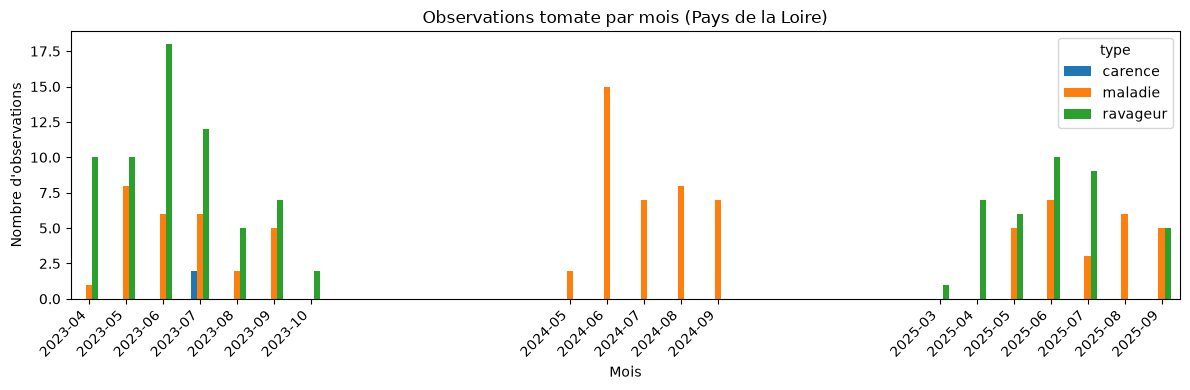

,debut,fin,semaine_debut,semaine_fin
annee,,,,
2023,2023-04-06,2023-10-05,14,40
2024,2024-05-16,2024-09-13,20,37
2025,2025-03-27,2025-09-18,13,38


Fenêtre retenue dans le moteur (poolée 2023–2025) :
  Semaine 13 → 40

Conclusion : tout bulletin publié hors de cette fenêtre produira
'Indéterminé / hors saison' et non 'Non corroboré' dans le moteur de compatibilité.


In [35]:
# Profil saisonnier : observations tomate par bulletin et par type
saisonnier = (
    obs_tomate[obs_tomate["region"] == "Pays de la Loire"]
    .groupby(["bulletin_id", "date_bulletin", "type"])
    .size()
    .reset_index(name="nb")
    .sort_values("date_bulletin")
)

display(saisonnier)

# Visualisation : nombre d'observations tomate par bulletin
pivot = (
    obs_tomate[obs_tomate["region"] == "Pays de la Loire"]
    .assign(mois=lambda df: df["date_bulletin"].dt.to_period("M"))
    .groupby(["mois", "type"])
    .size()
    .unstack(fill_value=0)
)

pivot.plot(kind="bar", figsize=(12, 4), title="Observations tomate par mois (Pays de la Loire)")
plt.xlabel("Mois")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Fenêtre saisonnière par année (documentation de la variabilité)
fenetre_par_an = (
    obs_tomate[obs_tomate["region"] == "Pays de la Loire"]
    .dropna(subset=["date_bulletin"])
    .assign(annee=lambda df: df["date_bulletin"].dt.year)
    .groupby("annee")["date_bulletin"]
    .agg(debut="min", fin="max")
)
fenetre_par_an["semaine_debut"] = fenetre_par_an["debut"].dt.isocalendar().week
fenetre_par_an["semaine_fin"] = fenetre_par_an["fin"].dt.isocalendar().week
display(fenetre_par_an)

print("Fenêtre retenue dans le moteur (poolée 2023–2025) :")
print(f"  Semaine {fenetre_par_an['semaine_debut'].min()} → {fenetre_par_an['semaine_fin'].max()}")
print()
print("Conclusion : tout bulletin publié hors de cette fenêtre produira")
print("'Indéterminé / hors saison' et non 'Non corroboré' dans le moteur de compatibilité.")


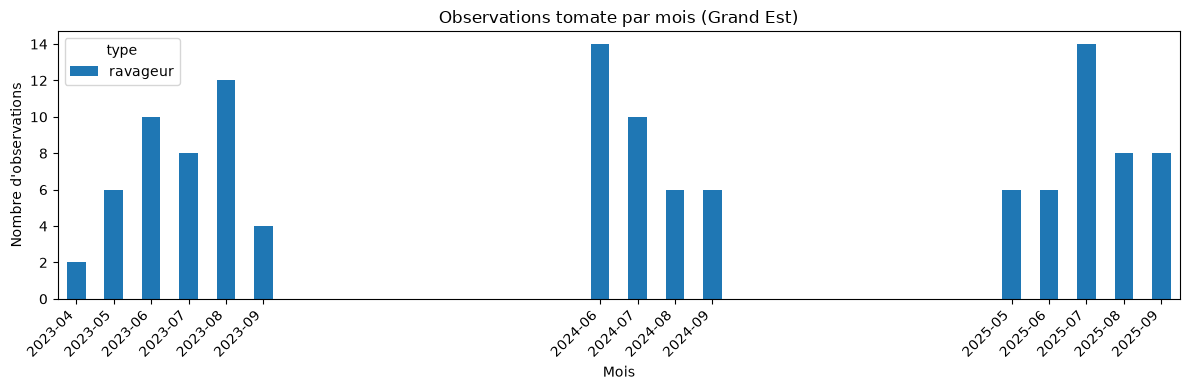

,debut,fin,semaine_debut,semaine_fin
annee,,,,
2023,2023-04-26,2023-09-20,17,38
2024,2024-06-05,2024-09-18,23,38
2025,2025-05-14,2025-09-10,20,37


Fenêtre retenue dans le moteur (poolée Grand Est) :
  Semaine 17 → 38

Conclusion : tout bulletin Grand Est publié hors de cette fenêtre produira
'Indéterminé / hors saison' et non 'Non corroboré' dans le moteur de compatibilité.


In [32]:
# Visualisation : observations tomate par mois — Grand Est
pivot_ge = (
    obs_tomate[obs_tomate["region"] == "Grand Est"]
    .assign(mois=lambda df: df["date_bulletin"].dt.to_period("M"))
    .groupby(["mois", "type"])
    .size()
    .unstack(fill_value=0)
)

pivot_ge.plot(kind="bar", figsize=(12, 4), title="Observations tomate par mois (Grand Est)")
plt.xlabel("Mois")
plt.ylabel("Nombre d'observations")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Fenêtre saisonnière par année — Grand Est
fenetre_par_an_ge = (
    obs_tomate[obs_tomate["region"] == "Grand Est"]
    .dropna(subset=["date_bulletin"])
    .assign(annee=lambda df: df["date_bulletin"].dt.year)
    .groupby("annee")["date_bulletin"]
    .agg(debut="min", fin="max")
)
fenetre_par_an_ge["semaine_debut"] = fenetre_par_an_ge["debut"].dt.isocalendar().week
fenetre_par_an_ge["semaine_fin"] = fenetre_par_an_ge["fin"].dt.isocalendar().week
display(fenetre_par_an_ge)

print("Fenêtre retenue dans le moteur (poolée Grand Est) :")
print(f"  Semaine {fenetre_par_an_ge['semaine_debut'].min()} → {fenetre_par_an_ge['semaine_fin'].max()}")
print()
print("Conclusion : tout bulletin Grand Est publié hors de cette fenêtre produira")
print("'Indéterminé / hors saison' et non 'Non corroboré' dans le moteur de compatibilité.")


## 11. Bulletins avec bioagresseurs liés aux 12 classes CNN

In [12]:
referentiel_cnn = read_csv_auto(REFERENTIEL_CNN_PATH)
display(referentiel_cnn)

def split_terms(value) -> list[str]:
    if pd.isna(value):
        return []
    return [term.strip() for term in re.split(r"[;|,]", str(value)) if term.strip()]

cnn_terms = []
for _, row in referentiel_cnn.iterrows():
    terms = []
    for col in ["nom_fr", "agent", "synonymes_bsv"]:
        if col in referentiel_cnn.columns:
            terms.extend(split_terms(row.get(col)))
    for term in terms:
        term_norm = normalize_text(term)
        if term_norm:
            cnn_terms.append({
                "classe_dataset": row.get("classe_dataset", ""),
                "terme": term,
                "terme_norm": term_norm,
            })

cnn_terms_df = pd.DataFrame(cnn_terms).drop_duplicates()
display(cnn_terms_df.sort_values(["classe_dataset", "terme"]))

matches = []
for obs_idx, obs in obs_norm.iterrows():
    haystack = f"{obs['bioagresseur_norm']} {obs['observation_norm']}"
    for _, term in cnn_terms_df.iterrows():
        pattern = rf"\b{re.escape(term['terme_norm'])}\b"
        if re.search(pattern, haystack):
            matches.append({
                "bulletin_id": obs["bulletin_id"],
                "region": obs["region"],
                "date_bulletin": obs["date_bulletin"],
                "culture": obs["culture"],
                "bioagresseur": obs["bioagresseur"],
                "classe_dataset": term["classe_dataset"],
                "terme_match": term["terme"],
                "observation": obs["observation"],
                "source_information": obs["source_information"],
            })

cnn_matches = pd.DataFrame(matches).drop_duplicates()
bulletins_cnn = bulletins[
    bulletins["bulletin_id"].isin(cnn_matches["bulletin_id"].unique())
].sort_values(["region", "date_bulletin"])

print(f"Observations liées aux classes CNN : {len(cnn_matches):,}")
print(f"Bulletins avec au moins une classe CNN : {len(bulletins_cnn):,}")
display(cnn_matches.sort_values(["classe_dataset", "region", "date_bulletin"]))
display(cnn_matches["classe_dataset"].value_counts().to_frame("nb_observations"))
display(bulletins_cnn)

,classe_dataset,cultures_concernées,nom_fr,agent,type,synonymes_bsv,hôtes
0,late_blight,tomate,Mildiou,Phytophthora infestans,maladie,mildiou;mildiou de la tomate;mildiou pomme de terre,tomate;pomme de terre
1,early_blight,tomate,Alternariose,Alternaria solani (syn. A. tomatophila); A. solani,maladie,alternariose;alternaria,tomate;pomme de terre;aubergine
2,septoria_leaf_spot,tomate,Septoriose,Septoria lycopersici,maladie,septoriose;taches septoriennes,tomate
3,leaf_mold,tomate,Cladosporiose,Passalora fulva,maladie,cladosporiose;moisissure des feuilles;passalora fulva,tomate
4,target_spot,tomate,Corynesporiose,Corynespora cassiicola,maladie,corynesporiose;target spot;tache cible,tomate;concombre;aubergine
5,verticillium_wilt,tomate,Verticilliose,Verticillium dahliae,maladie,verticilliose;flétrissement verticillien,tomate;pomme de terre;aubergine;fraisier
6,bacterial_spot,tomate,Taches bactériennes,Xanthomonas spp.,maladie,taches bactériennes;bactériose;xanthomonas,tomate;poivron
7,mosaic_virus,tomate,Mosaïque de la tomate,Tomato mosaic virus (ToMV),maladie,mosaïque;virus de la mosaïque;tomato mosaic virus,tomate;poivron
8,yellow_leaf_curl_virus,tomate,Virus des feuilles jaunes en cuillère,Tomato yellow leaf curl virus (TYLCV),maladie,tylcv;virus des feuilles jaunes en cuillère;yellow leaf curl,tomate
9,spider_mites_two_spotted_spider_mite,tomate,Araignée rouge à deux points,Tetranychus urticae,ravageur,araignée rouge;acariens;tétranyque;tetranychus urticae,tomate;concombre;haricot;fraisier


,classe_dataset,terme,terme_norm
28,bacterial_spot,Taches bactériennes,taches bacteriennes
29,bacterial_spot,Xanthomonas spp.,xanthomonas spp
31,bacterial_spot,bactériose,bacteriose
30,bacterial_spot,taches bactériennes,taches bacteriennes
32,bacterial_spot,xanthomonas,xanthomonas
7,early_blight,A. solani,a solani
6,early_blight,Alternaria solani (syn. A. tomatophila),alternaria solani syn a tomatophila
5,early_blight,Alternariose,alternariose
9,early_blight,alternaria,alternaria
8,early_blight,alternariose,alternariose


Observations liées aux classes CNN : 1,636
Bulletins avec au moins une classe CNN : 156


,bulletin_id,region,date_bulletin,culture,bioagresseur,classe_dataset,terme_match,observation,source_information
61,grandest_2023_bsv12,Grand Est,2023-07-05,salade,Botrytis,bacterial_spot,bactériose,Salade conventionnelle plein champ dans le secteur Toul Nord : irrigation identique sur jeunes salades et salades matures. L’irrigation importante (fort bes...,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV12_LEG_GE_S27_2023.txt#L560
70,grandest_2023_bsv13,Grand Est,2023-07-12,salade,Botrytis,bacterial_spot,bactériose,Salade conventionnelle plein champ dans le secteur Toul Nord : irrigation identique sur jeunes salades et salades matures. L’irrigation importante (fort bes...,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV13_LEG_GE_S28_2023.txt#L590
78,grandest_2023_bsv14,Grand Est,2023-07-19,salade,Botrytis,bacterial_spot,bactériose,"Pas d’observation cette semaine. L’irrigation importante (fort besoin d’irrigation des jeunes séries) amène un surplus d’humidité sur salades matures, et l’...",outputs/extracted_text/grandest/legumes_maraichage/2023/BSV14_LEG_GE_S29_2023.txt#L669
88,grandest_2023_bsv15,Grand Est,2023-07-26,salade,Botrytis,bacterial_spot,bactériose,"Pas d’observation cette semaine. L’irrigation importante (fort besoin d’irrigation des jeunes séries) amène un surplus d’humidité sur salades matures, et l’...",outputs/extracted_text/grandest/legumes_maraichage/2023/BSV15_LEG_GE_S30_2023.txt#L545
98,grandest_2023_bsv16,Grand Est,2023-08-02,salade,Botrytis,bacterial_spot,bactériose,Observations ponctuelles de botrytis sur une parcelles secteur Toul-Sud. Les récentes précipitations et l’humidité de l’air favorisent l’apparition et la di...,outputs/extracted_text/grandest/legumes_maraichage/2023/BSV16_LEG_GE_S31_2023.txt#L543
...,...,...,...,...,...,...,...,...,...
1541,pdl_2025_bsv22,Pays de la Loire,2025-08-20,aubergine,Verticilliose,verticillium_wilt,verticilliose,Présence à Saumur (49),outputs/tables/pdl/maraichage/2025/BSV_maraichage_no_22_20250820/page_11_table_1.csv
1557,pdl_2025_bsv23,Pays de la Loire,2025-09-04,aubergine,Verticilliose,verticillium_wilt,Verticilliose,Présence à Saumur (49),outputs/tables/pdl/maraichage/2025/BSV_maraichage_no_23_20250904/page_13_table_1.csv
1558,pdl_2025_bsv23,Pays de la Loire,2025-09-04,aubergine,Verticilliose,verticillium_wilt,verticilliose,Présence à Saumur (49),outputs/tables/pdl/maraichage/2025/BSV_maraichage_no_23_20250904/page_13_table_1.csv
1574,pdl_2025_bsv24,Pays de la Loire,2025-09-18,aubergine,Verticilliose,verticillium_wilt,Verticilliose,Présence à Saumur (49) et à St-Barthélémy-d’Anjou (49),outputs/tables/pdl/maraichage/2025/BSV_maraichage_no_24_20250918/page_12_table_2.csv


,nb_observations
classe_dataset,
late_blight,896
spider_mites_two_spotted_spider_mite,204
septoria_leaf_spot,188
leaf_mold,116
early_blight,98
verticillium_wilt,66
bacterial_spot,63
mosaic_virus,4
healthy,1


,bulletin_id,region,date_bulletin,template_id,nature_meteo,meteo_extraction_status,meteo_extraction_method,meteo_extraction_score,periode_prevision_meteo,prevision_meteo
0,grandest_2023_bsv01,Grand Est,2023-04-19,grand_est_standard,prevision,image_seule,general:weather_source,11,20/04/2023-26/04/2023,"(Source : Météo France, commune de Innenheim, 19/04/2023 à 14h30. Retrouvez les données météo actualisées ici)  Oignon et Pomme de terre (Source : Météo Fr..."
1,grandest_2023_bsv02,Grand Est,2023-04-26,grand_est_standard,prevision,image_seule,general:weather_source,11,27/04/2023-03/05/2023,"(Source : Météo France, commune de Innenheim, 19/04/2023 à 11h10. Retrouvez les données météo actualisées ici)  Oignon et Pomme de terre (Source : Météo Fr..."
2,grandest_2023_bsv03,Grand Est,2023-05-04,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,15,05/05/2023-11/05/2023,"• Laitue, solanacées et cucurbitacées sous abri (Source : Météo France, commune de Nancy, 04/05/2023 à 10h49. Retrouvez les données météo actualisées ici)"
3,grandest_2023_bsv04,Grand Est,2023-05-11,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,12,12/05/2023-18/05/2023,"(Source : Météo France, ville de Allibaudières, 11/05/2023 à 13h45. Retrouvez les données météo actualisées ici)"
4,grandest_2023_bsv06,Grand Est,2023-05-24,grand_est_standard,prevision,image_seule,general:heading:DONNEES METEO,15,25/05/2023-31/05/2023," Laitue, solanacées et cucurbitacées sous abri (Source : Météo France, commune de Lunéville, 24/05/2023 à 9h50. Retrouvez les données météo actualisées ici..."
...,...,...,...,...,...,...,...,...,...,...
152,pdl_2025_bsv28,Pays de la Loire,2025-10-16,pdl_2025_prevision_risque,prevision,lisible,general:heading:PREVISION METEOROLOGIQUE,27,16/10/2025-22/10/2025,Chemillé— Chaillé-lesSt-Philbert-deChallans (85) Allonnes (49) Valanjou (49) Marais (85) Grand -Lieu (44) La Planche (44) Laval (53) Le Mans (72) Les tempér...
153,pdl_2025_bsv29,Pays de la Loire,2025-10-30,pdl_2025_prevision_risque,prevision,lisible,general:heading:PREVISION METEOROLOGIQUE,25,30/10/2025-05/11/2025,Allonnes (49) Chemillé—Valanjou (49) Challans (85) Chaillé-les-Marais (85) St-Philbert-de-Grand -Lieu (44) La Planche (44) Laval (53) Le Mans (72) Les condi...
154,pdl_2025_bsv30,Pays de la Loire,2025-11-13,pdl_2025_prevision_risque,prevision,lisible,general:heading:PREVISION METEOROLOGIQUE,27,13/11/2025-19/11/2025,Allonnes (49) Chemillé—Valanjou (49) Challans (85) Chaillé-les-Marais (85) St-Philbert-de-Grand -Lieu (44) La Planche (44) Laval (53) Le Mans (72) Les condi...
155,pdl_2025_bsv31,Pays de la Loire,2025-12-04,pdl_2025_prevision_risque,prevision,lisible,general:heading:PREVISION METEOROLOGIQUE,27,04/12/2025-10/12/2025,Allonnes (49) Chemillé—Valanjou (49) Challans (85) Chaillé-les-Marais (85) St-Philbert-de-Grand -Lieu (44) La Planche (44) Laval (53) Le Mans (72) Les condi...


## 12. Classes CNN absentes du corpus BSV

Certaines classes CNN ne produiront jamais de signal dans ce corpus, non parce que le BSV les contredit, mais parce qu'elles ne sont pas couvertes par le réseau d'observation. C'est une limite à documenter, pas un désaccord.

In [13]:
# Classes CNN présentes vs absentes dans bsv_observations
if "cnn_matches" in dir() and len(cnn_matches) > 0:
    classes_presentes = set(cnn_matches["classe_dataset"].unique())
else:
    classes_presentes = set()

if "referentiel_cnn" in dir():
    toutes_classes = set(referentiel_cnn["classe_dataset"].dropna().unique())
else:
    toutes_classes = {
        "late_blight", "early_blight", "septoria_leaf_spot", "leaf_mold",
        "target_spot", "verticillium_wilt", "bacterial_spot", "mosaic_virus",
        "yellow_leaf_curl_virus", "spider_mites_two_spotted_spider_mite",
        "leaf_blight", "healthy"
    }

classes_absentes = toutes_classes - classes_presentes - {"healthy"}

print("Classes CNN avec au moins un signal BSV :")
for c in sorted(classes_presentes):
    print(f"  ✓ {c}")

print()
print("Classes CNN sans signal dans ce corpus (→ 'Indéterminé', pas 'Désaccord') :")
for c in sorted(classes_absentes):
    print(f"  ✗ {c}")

print()
print("Note : 'healthy' est hors logique de compatibilité.")
print("Note : 'leaf_blight' (agent indéterminé) est inclus dans le matching sur symptôme")
print("       via les synonymes 'brûlure foliaire' et 'nécrose foliaire'.")


Classes CNN avec au moins un signal BSV :
  ✓ bacterial_spot
  ✓ early_blight
  ✓ healthy
  ✓ late_blight
  ✓ leaf_mold
  ✓ mosaic_virus
  ✓ septoria_leaf_spot
  ✓ spider_mites_two_spotted_spider_mite
  ✓ verticillium_wilt

Classes CNN sans signal dans ce corpus (→ 'Indéterminé', pas 'Désaccord') :
  ✗ leaf_blight
  ✗ target_spot
  ✗ yellow_leaf_curl_virus

Note : 'healthy' est hors logique de compatibilité.
Note : 'leaf_blight' (agent indéterminé) est inclus dans le matching sur symptôme
       via les synonymes 'brûlure foliaire' et 'nécrose foliaire'.


## 13. Bioagresseurs observés sur tomate

Quels bioagresseurs sont signalés sur tomate, avec quelle fréquence, et comment se répartissent-ils entre ravageurs et maladies ?
Cette section est le point d'entrée pour calibrer le référentiel CNN–BSV sur la culture pilote.


Observations tomate liées aux classes CNN : 97
Bulletins avec au moins une classe CNN (tomate) : 34


,bulletin_id,region,date_bulletin,culture,bioagresseur,classe_dataset,terme_match,observation,source_information
0,pdl_2023_bsv06,Pays de la Loire,2023-04-13,tomate,Mildiou,late_blight,Mildiou,Des dégâts de mildiou sur collet sont observés sur; 5% des plants de tomate à L'Ile-d'Olonne (85); Les curseurs de risque utilisés ont pour objectif de synt...,outputs/extracted_text/pdl/maraichage/2023/BSV_maraichage_no_06_20230413.txt#L331
1,pdl_2023_bsv06,Pays de la Loire,2023-04-13,tomate,Mildiou,late_blight,mildiou,Des dégâts de mildiou sur collet sont observés sur; 5% des plants de tomate à L'Ile-d'Olonne (85); Les curseurs de risque utilisés ont pour objectif de synt...,outputs/extracted_text/pdl/maraichage/2023/BSV_maraichage_no_06_20230413.txt#L331
2,pdl_2023_bsv09,Pays de la Loire,2023-05-04,tomate,Mildiou,late_blight,Mildiou,"En parcelle de tomate à Bourneau (85), des dégâts de mildiou du pied ont été observés sur; 5% des plants",outputs/extracted_text/pdl/maraichage/2023/BSV_maraichage_no_09_20230504.txt#L297
3,pdl_2023_bsv09,Pays de la Loire,2023-05-04,tomate,Mildiou,late_blight,mildiou,"En parcelle de tomate à Bourneau (85), des dégâts de mildiou du pied ont été observés sur; 5% des plants",outputs/extracted_text/pdl/maraichage/2023/BSV_maraichage_no_09_20230504.txt#L297
28,pdl_2023_flash01,Pays de la Loire,2023-05-17,tomate,Mildiou,late_blight,Mildiou,"sont favorables à une contamination des cultures de céleri Sur la culture de tomate à Cholet (49), la pression mildioupar la septoriose : est forte",outputs/extracted_text/pdl/maraichage/2023/BSV_maraichage_flash_no_01_20230517.txt#L198
...,...,...,...,...,...,...,...,...,...
32,pdl_2023_flash01,Pays de la Loire,2023-05-17,tomate,septoriose,septoria_leaf_spot,Septoriose,"sont favorables à une contamination des cultures de céleri Sur la culture de tomate à Cholet (49), la pression mildioupar la septoriose : est forte",outputs/extracted_text/pdl/maraichage/2023/BSV_maraichage_flash_no_01_20230517.txt#L198
33,pdl_2023_flash01,Pays de la Loire,2023-05-17,tomate,septoriose,septoria_leaf_spot,septoriose,"sont favorables à une contamination des cultures de céleri Sur la culture de tomate à Cholet (49), la pression mildioupar la septoriose : est forte",outputs/extracted_text/pdl/maraichage/2023/BSV_maraichage_flash_no_01_20230517.txt#L198
80,pdl_2025_bsv20,Pays de la Loire,2025-07-17,tomate,Acariens tétranyques,spider_mites_two_spotted_spider_mite,acariens,Tomates : présence à Sèvremoine (49) Aubergines : forte pression à Sèvremoine (49); 100% des plants à Loire-Authion (49),outputs/tables/pdl/maraichage/2025/BSV_maraichage_no_20_20250717/page_13_table_1.csv
89,pdl_2025_bsv23,Pays de la Loire,2025-09-04,tomate,Acariens tétranyques,spider_mites_two_spotted_spider_mite,acariens,Tomates :,outputs/tables/pdl/maraichage/2025/BSV_maraichage_no_23_20250904/page_11_table_1.csv


,nb_observations
classe_dataset,
late_blight,56
leaf_mold,34
septoria_leaf_spot,4
spider_mites_two_spotted_spider_mite,3


,bioagresseur,type,nb_observations,nb_bulletins
21,Pucerons,ravageur,56,35
38,"Thrips, pucerons et acariens",ravageur,40,15
10,Mildiou,maladie,34,28
19,Puceron,ravageur,18,15
39,Tuta absoluta,ravageur,18,18
5,Botrytis,maladie,17,16
6,Cladosporiose,maladie,17,17
17,Oïdium,maladie,13,13
35,Thrips,ravageur,11,7
22,Pucerons et Acariens,ravageur,10,4


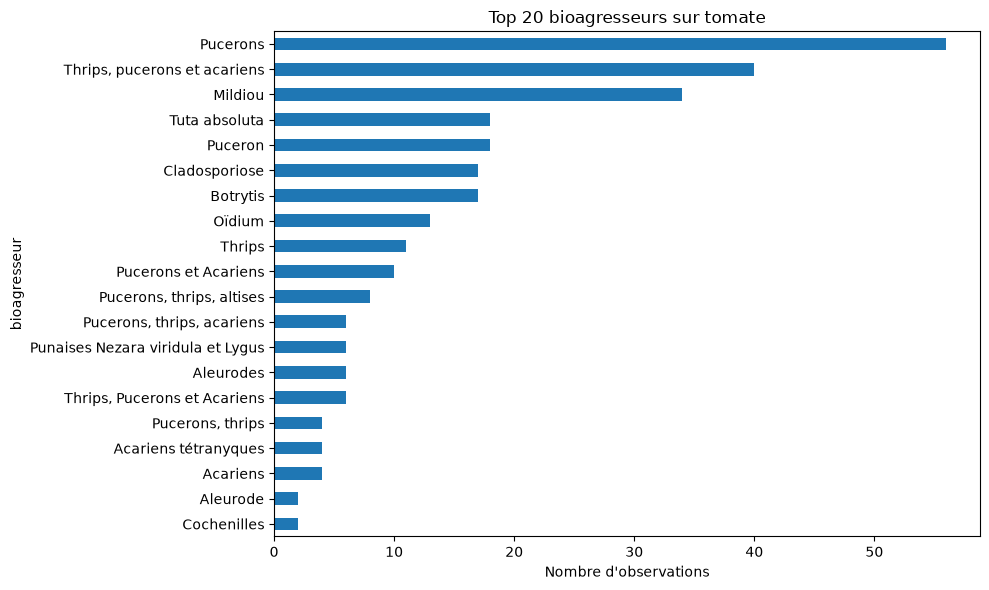

In [14]:
# Lookup sur les observations du corpus uniquement pour tomate
matches_tomate = [m for m in matches if m["culture"] == "tomate"]
cnn_matches_tomate = pd.DataFrame(matches_tomate).drop_duplicates()

bulletins_cnn_tomate = bulletins[
    bulletins["bulletin_id"].isin(cnn_matches_tomate["bulletin_id"].unique())
].sort_values(["region", "date_bulletin"])

print(f"Observations tomate liées aux classes CNN : {len(cnn_matches_tomate):,}")
print(f"Bulletins avec au moins une classe CNN (tomate) : {len(bulletins_cnn_tomate):,}")
display(cnn_matches_tomate.sort_values(["classe_dataset", "region", "date_bulletin"]))
display(cnn_matches_tomate["classe_dataset"].value_counts().to_frame("nb_observations"))

# Fréquence des bioagresseurs sur tomate
bio_tomate = (
    obs_tomate.groupby(["bioagresseur", "type"])
    .agg(
        nb_observations=("bulletin_id", "count"),
        nb_bulletins=("bulletin_id", "nunique"),
    )
    .reset_index()
    .sort_values("nb_observations", ascending=False)
)
display(bio_tomate.head(30))

ax = bio_tomate.set_index("bioagresseur")["nb_observations"].head(20).sort_values().plot(
    kind="barh", figsize=(10, 6)
)
ax.set_title("Top 20 bioagresseurs sur tomate")
ax.set_xlabel("Nombre d'observations")
plt.tight_layout()
plt.show()


## 14. Chronologie des signalements tomate

Pour chaque bioagresseur d'intérêt, à quelle date apparaît-il dans les bulletins ?
On visualise la présence de chaque bioagresseur semaine par semaine.


,annee_semaine,region,bioagresseur,nb
0,2023-S14,Pays de la Loire,Puceron,1
1,2023-S15,Pays de la Loire,Mildiou,1
2,2023-S15,Pays de la Loire,Puceron,3
3,2023-S15,Pays de la Loire,Taupin,2
4,2023-S16,Pays de la Loire,Doryphore,1
5,2023-S16,Pays de la Loire,Puceron,1
6,2023-S17,Grand Est,Pucerons,2
7,2023-S17,Pays de la Loire,Puceron,1
8,2023-S17,Pays de la Loire,Thrips,1
9,2023-S18,Grand Est,Pucerons,2


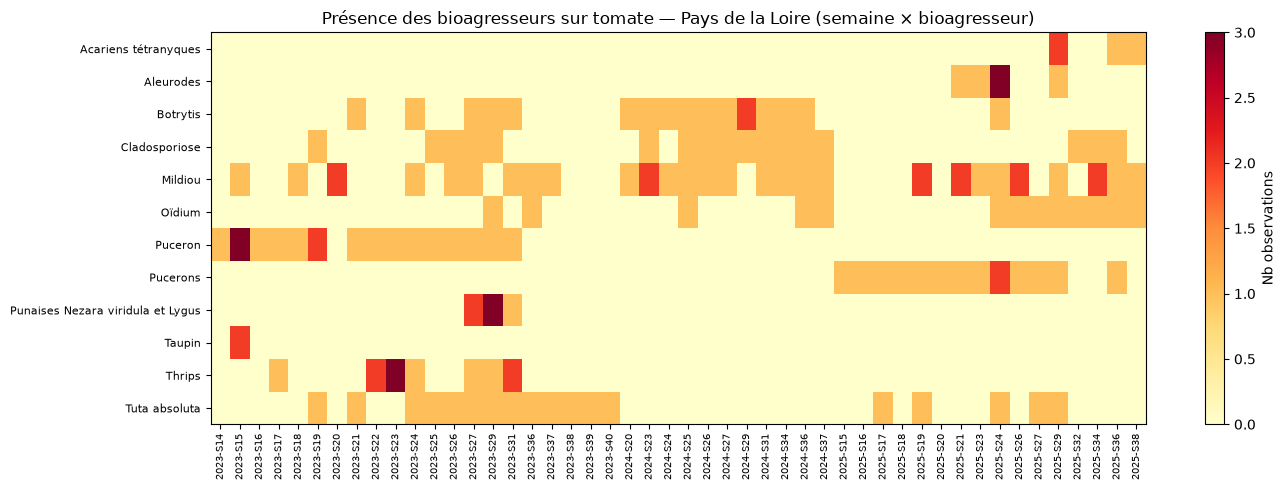

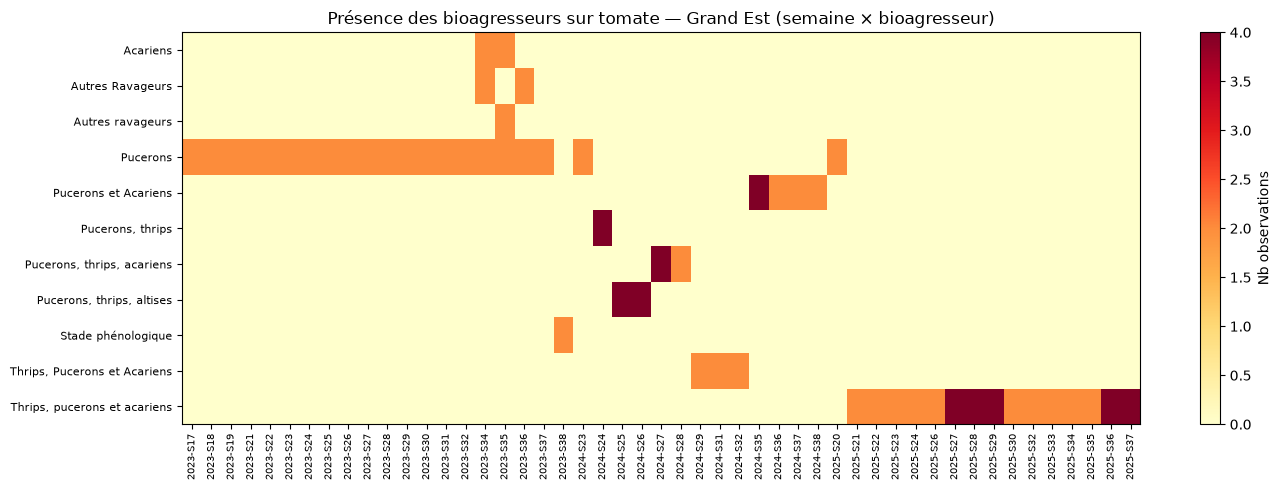

In [15]:
# Semaine ISO de chaque observation tomate
obs_tomate_dated = obs_tomate.dropna(subset=["date_bulletin"]).copy()
obs_tomate_dated["semaine"] = obs_tomate_dated["date_bulletin"].dt.isocalendar().week.astype(int)
obs_tomate_dated["annee"] = obs_tomate_dated["date_bulletin"].dt.year
obs_tomate_dated["annee_semaine"] = (
    obs_tomate_dated["annee"].astype(str) + "-S"
    + obs_tomate_dated["semaine"].astype(str).str.zfill(2)
)

# Chronologie : nb d'observations par semaine et par bioagresseur
chrono = (
    obs_tomate_dated.groupby(["annee_semaine", "region", "bioagresseur"])
    .size()
    .reset_index(name="nb")
    .sort_values("annee_semaine")
)
display(chrono.head(40))

# Heatmap par région
for region in ["Pays de la Loire", "Grand Est"]:
    df_region = obs_tomate_dated[obs_tomate_dated["region"] == region]

    if df_region.empty:
        print(f"Aucune observation tomate pour {region}")
        continue

    top_bio_region = df_region["bioagresseur"].value_counts().head(12).index
    pivot_region = (
        df_region[df_region["bioagresseur"].isin(top_bio_region)]
        .groupby(["annee_semaine", "bioagresseur"])
        .size()
        .unstack(fill_value=0)
        .sort_index()
    )

    fig, ax = plt.subplots(figsize=(14, 5))
    im = ax.imshow(pivot_region.T.values, aspect="auto", cmap="YlOrRd")
    ax.set_xticks(range(len(pivot_region.index)))
    ax.set_xticklabels(pivot_region.index, rotation=90, fontsize=7)
    ax.set_yticks(range(len(pivot_region.columns)))
    ax.set_yticklabels(pivot_region.columns, fontsize=8)
    ax.set_title(f"Présence des bioagresseurs sur tomate — {region} (semaine × bioagresseur)")
    plt.colorbar(im, ax=ax, label="Nb observations")
    plt.tight_layout()
    plt.show()


## 15. Météo associée aux bulletins avec observations tomate

Les bulletins contenant des observations tomate ont-ils une météo exploitable ?
On croise le statut d'extraction météo (`meteo_extraction_status`) et les prévisions textuelles disponibles.


In [16]:
# Statut météo pour les bulletins avec tomate
meteo_cols = [
    "bulletin_id", "region", "date_bulletin",
    "nature_meteo", "meteo_extraction_status",
    "meteo_extraction_method", "meteo_extraction_score",
    "periode_prevision_meteo", "prevision_meteo",
]
meteo_tomate = bulletins_avec_tomate[
    [c for c in meteo_cols if c in bulletins_avec_tomate.columns]
].copy()

print("Statut météo dans les bulletins avec observations tomate :")
display(meteo_tomate["meteo_extraction_status"].value_counts().to_frame("nb"))

print("\nRépartition région × statut météo :")
display(
    meteo_tomate.groupby(["region", "meteo_extraction_status"]).size()
    .unstack(fill_value=0)
)

print("\nExemples de prévisions textuelles lisibles :")
display(
    meteo_tomate[meteo_tomate["meteo_extraction_status"] == "lisible"]
    [["bulletin_id", "region", "date_bulletin", "prevision_meteo"]]
    .dropna(subset=["prevision_meteo"])
    .head(15)
)


Statut météo dans les bulletins avec observations tomate :


,nb
meteo_extraction_status,
lisible,50
image_seule,49



Répartition région × statut météo :


meteo_extraction_status,image_seule,lisible
region,,
Grand Est,49,0
Pays de la Loire,0,50



Exemples de prévisions textuelles lisibles :


,bulletin_id,region,date_bulletin,prevision_meteo
69,pdl_2023_bsv05,Pays de la Loire,2023-04-06,"Altise, Mouches, Mildiou Carotte -Fenouil-Panais P.4 Source : Weather Measures Mouches Pluviométrie 2023 T min (S 13) T max (S 13) Cucurbitacées P.5 mm (S 1..."
70,pdl_2023_bsv06,Pays de la Loire,2023-04-13,"Altise, Teigne des crucifères Carotte -Fenouil-Panais P.3 Source : Weather Measures Mouches Pluviométrie 2023 T min (S 14) T max (S 14) Cucurbitacées P.4 mm..."
71,pdl_2023_bsv07,Pays de la Loire,2023-04-20,"Altise, Xenostrongylus deyrollei Source : Weather Measures Carotte - Panais P.3 Mouche mineuse du céleri Pluviométrie 2023 T min (S 15) T max (S 15) mm (S 1..."
72,pdl_2023_bsv08,Pays de la Loire,2023-04-27,"Altise, Mouche Carotte - Panais - Fenouil P.3 Source : Weather Measures Mouche Pluviométrie 2023 T min (S 16) T max (S 16) Cucurbitacées P.4 mm (S 16) Pucer..."
73,pdl_2023_bsv09,Pays de la Loire,2023-05-04,"Altise, Xenostrongylus Carotte - Panais - Fenouil P.3 Source : Weather Measures Mouche Pluviométrie 2023 T min (S 17) T max (S 17) Cucurbitacées P.4 mm (S 1..."
74,pdl_2023_bsv10,Pays de la Loire,2023-05-11,"Altise, Mildiou Carotte - Céleri P.4 Source : Weather Measures Situation calme Pluviométrie 2023 T min (S 18) T max (S 18) Cucurbitacées P.4 mm (S 18) Pucer..."
75,pdl_2023_flash01,Pays de la Loire,2023-05-17,"Source : Weather Measures Pluviométrie 2023 T min (S 19) T max (S 19) mm (S 19) Allonnes (49) 232,4 mm (+18,6) 7,2°C 22,5°C Challans (85) 207 mm (+18,0) 10°..."
76,pdl_2023_bsv11,Pays de la Loire,2023-05-25,"Altise, Mouches Carotte - Panais Source : Weather Measures porte-graine P.4 Puceron Pluviométrie 2023 T min (S 20) T max (S 20) mm (S 20) Cucurbitacées P.4 ..."
77,pdl_2023_bsv12,Pays de la Loire,2023-06-01,"Altise, Mouches Carotte - Céleri P.4 Source : Weather Measures Mouche de la carotte Pluviométrie 2023 T min (S 21) T max (S 21) Cucurbitacées P.4 mm (S 21) ..."
78,pdl_2023_bsv13,Pays de la Loire,2023-06-08,Altise Carotte - Céleri P.3 Source : Weather Measures Mouche mineuse du céleri Pluviométrie 2023 T min (S 22) T max (S 22) Cucurbitacées P.4 mm (S 22) Pucer...


## 16. Niveau de risque et analyse de risque sur tomate

Les observations tomate contiennent-elles des informations sur le niveau de risque ou des analyses de risque ? Ces champs alimentent directement le moteur de compatibilité.


In [39]:
# Niveau de risque renseigné
print("Niveau de risque renseigné :")
display(obs_tomate["niveau_risque_observation"].replace("", float("nan")).value_counts(dropna=False).to_frame("nb"))

print("\nAnalyse de risque renseignée :")
display(obs_tomate["analyse_risque"].replace("", float("nan")).value_counts(dropna=False).head(20).to_frame("nb"))

print("\nFacteurs favorables renseignés :")
display(obs_tomate["facteurs_favorables"].replace("", float("nan")).value_counts(dropna=False).head(20).to_frame("nb"))

# Observations tomate avec au moins un champ risque renseigné
obs_tomate_risque = obs_tomate[
    obs_tomate["niveau_risque_observation"].fillna("").ne("")
    | obs_tomate["analyse_risque"].fillna("").ne("")
    | obs_tomate["facteurs_favorables"].fillna("").ne("")
].copy()

print(f"\nObservations tomate avec au moins un champ risque : {len(obs_tomate_risque):,}")
display(
    obs_tomate_risque[[
        "bulletin_id", "date_bulletin", "bioagresseur",
        "niveau_risque_observation", "analyse_risque", "facteurs_favorables", "observation"
    ]].head(20)
)

total = len(obs_tomate)
avec_risque = obs_tomate["niveau_risque_observation"].fillna("").ne("").sum()
print(f"Observations tomate avec niveau de risque : {avec_risque} / {total} ({100*avec_risque/total:.1f}%)")
print(f"Observations tomate sans niveau de risque : {total - avec_risque} / {total} ({100*(total-avec_risque)/total:.1f}%)")

print("\nTaux de renseignement du niveau de risque par template :")
display(
    obs_tomate.merge(
        bulletins[["bulletin_id", "template_id"]], on="bulletin_id", how="left"
    ).groupby("template_id")["niveau_risque_observation"]
    .apply(lambda s: f"{s.fillna('').ne('').sum()} / {len(s)} ({s.fillna('').ne('').mean():.0%})")
    .to_frame("taux_renseigne")
)

Niveau de risque renseigné :


,nb
niveau_risque_observation,
NaN,202
fort,71
en_hausse,26
moyen,16
tres_fort,6
faible,4



Analyse de risque renseignée :


,nb
analyse_risque,
NaN,194
Les champignons se développent très rapidement avec une forte humidité relative sous abris très favorable. Le risque est élevé.,20
"Le nombre d’individus observés est en hausse sur solanacées et se développent sur les autres cultures sous abris. Le risque pour la culture est en hausse avec le temps plus chaud prévu. En effet, la diffusion peut être rapide et les auxiliaires commencent à peine à être observés. La présence d'individus ailés confirme qu'une dynamique de diffusion est en cours.",6
"Lorsque la régulation par auxiliaire n’a pas suffi, le nombre d’individus observés est en hausse sur solanacées et cucurbitacées et peut se développer sur les autres cultures sous abris. Le risque pour la culture est en hausse avec la météo chaude sans être trop sèche. La diffusion peut être rapide. La présence d'individus ailés confirme qu'une dynamique de diffusion est en cours.",4
Les champignons se développent très rapidement avec des conditions sous abris très favorables. Le risque est très élevé.,4
"Le risque actuel pour les cultures est plus fort du fait des températures. Les maximales se situent autour de 30°C dans les prochains jours, température idéale pour le développement des thrips. Vigilance. Le risque est élevé.",4
"Le climat plus doux, avec de plus fortes amplitudes de températures peuvent être favorable au développement de certaines maladies fongiques. Le risque est fort pour les jours à venir.",4
"Le risque actuel pour les cultures est plus fort du fait des températures. Les températures seront idéales sous abri pour le développement des thrips, pucerons et acariens. Vigilance. Le risque est élevé si l’on tient compte des observations de la semaine passée.",4
"(C. VARAILLAS, le 07/07) Le risque actuel pour les cultures est plus fort du fait des températures. Le temps chaud et sec est propice au développement des acariens tétranyques et du thrips. Vigilance. Le risque est élevé si l’on tient compte des observations de la semaine passée et de la chaleur qui se maintient.",4



Facteurs favorables renseignés :


,nb
facteurs_favorables,
NaN,206
Les champignons se développent très rapidement avec une forte humidité relative sous abris très favorable,22
Le risque pour la culture est en hausse avec le temps plus chaud prévu,6
Le risque pour la culture est en hausse avec la météo chaude sans être trop sèche,4
"Risque toujours présent, temps encore favorable",4
Les champignons se développent très rapidement avec des conditions sous abris très favorables,4
"Le risque actuel pour les cultures est plus fort du fait des températures; Les maximales se situent autour de 30°C dans les prochains jours, température idéale pour le développement des thrips",4
"Le climat plus doux, avec de plus fortes amplitudes de températures peuvent être favorable au développement de certaines maladies fongiques",4
Une forte humidité de l’air avec de plus fortes amplitudes de températures peuvent être favorables au développement de certaines maladies fongiques,4



Observations tomate avec au moins un champ risque : 131


,bulletin_id,date_bulletin,bioagresseur,niveau_risque_observation,analyse_risque,facteurs_favorables,observation
6,grandest_2023_bsv02,2023-04-26,Pucerons,en_hausse,"Le nombre d’individus observés est fort, le risque pour la culture est en forte hausse du fait des températures qui s’adoucissent et des plantations en cours.","Le nombre d’individus observés est fort, le risque pour la culture est en forte hausse du fait des températures qui s’adoucissent et des plantations en cours","Quelques pucerons observés sur concombre sous abri au nord de Nancy la semaine passée. Cette semaine, aucune observation de puceron sur solanacées et cucurb..."
11,grandest_2023_bsv02,2023-04-26,Pucerons,en_hausse,"Le nombre d’individus observés est fort, le risque pour la culture est en forte hausse du fait des températures qui s’adoucissent et des plantations en cours.","Le nombre d’individus observés est fort, le risque pour la culture est en forte hausse du fait des températures qui s’adoucissent et des plantations en cours","Quelques pucerons observés sur concombre sous abri au nord de Nancy la semaine passée. Cette semaine, aucune observation de puceron sur solanacées et cucurb..."
14,grandest_2023_bsv03,2023-05-04,Pucerons,en_hausse,"Le nombre d’individus observés est en hausse, le risque pour la culture est en légère hausse du fait des températures qui s’adoucissent et des plantations e...","Le nombre d’individus observés est en hausse, le risque pour la culture est en légère hausse du fait des températures qui s’adoucissent et des plantations e...",Quelques pucerons observés sur concombre sous abri dans le Toulois. Aucune observation de puceron sur les jeunes solanacées mais de nombreux individus ont é...
22,grandest_2023_bsv03,2023-05-04,Pucerons,en_hausse,"Le nombre d’individus observés est en hausse, le risque pour la culture est en légère hausse du fait des températures qui s’adoucissent et des plantations e...","Le nombre d’individus observés est en hausse, le risque pour la culture est en légère hausse du fait des températures qui s’adoucissent et des plantations e...",Quelques pucerons observés sur concombre sous abri dans le Toulois. Aucune observation de puceron sur les jeunes solanacées mais de nombreux individus ont é...
25,grandest_2023_bsv04,2023-05-11,Pucerons,en_hausse,Le nombre d’individus observés est en hausse sur solanacées et se développent sur les autres cultures sous abris. Le risque pour la culture est en légère ha...,Le risque pour la culture est en légère hausse même si les températures restent encore un peu faibles,"Les premiers pucerons ont été observés sur culture de solanacées, notamment sur culture de tomate et principalement sur culture d’aubergine. Les pressions s..."
35,grandest_2023_bsv04,2023-05-11,Pucerons,en_hausse,Le nombre d’individus observés est en hausse sur solanacées et se développent sur les autres cultures sous abris. Le risque pour la culture est en légère ha...,Le risque pour la culture est en légère hausse même si les températures restent encore un peu faibles,"Les premiers pucerons ont été observés sur culture de solanacées, notamment sur culture de tomate et principalement sur culture d’aubergine. Les pressions s..."
39,grandest_2023_bsv06,2023-05-24,Pucerons,en_hausse,Le nombre d’individus observés est en hausse sur solanacées et se développent sur les autres cultures sous abris. Le risque pour la culture est en hausse av...,Le risque pour la culture est en hausse avec le temps plus chaud prévu,"Secteur de Pont-à-Mousson, début de pression en pucerons verts sur tomate (présence assez faible) au voisinage d’une culture de fraise très atteinte. Pressi..."
49,grandest_2023_bsv06,2023-05-24,Pucerons,en_hausse,Le nombre d’individus observés est en hausse sur solanacées et se développent sur les autres cultures sous abris. Le risque pour la culture est en hausse av...,Le risque pour la culture est en hausse avec le temps plus chaud prévu,"Secteur de Pont-à-Mousson, début de pression en pucerons 

Observations tomate avec niveau de risque : 123 / 325 (37.8%)
Observations tomate sans niveau de risque : 202 / 325 (62.2%)

Taux de renseignement du niveau de risque par template :


,taux_renseigne
template_id,
grand_est_standard,116 / 128 (91%)
pdl_2023_bilan,7 / 94 (7%)
pdl_2024_prevision,0 / 39 (0%)
pdl_2025_prevision_risque,0 / 64 (0%)


## 17. Indicateurs quantitatifs sur tomate

Quelles observations contiennent des pourcentages ou des comptages d'individus ?
Ce sont les observations les plus exploitables pour qualifier un niveau de pression.


In [28]:
# Observations avec indicateur quantitatif non vide
obs_tomate_quant = obs_tomate[
    obs_tomate["indicateur_quantitatif"].notna()
    & obs_tomate["indicateur_quantitatif"].ne("")
].copy()

print(f"Observations tomate avec indicateur quantitatif : {len(obs_tomate_quant):,} / {len(obs_tomate):,}")
display(
    obs_tomate_quant[[
        "bulletin_id", "date_bulletin", "bioagresseur",
        "indicateur_quantitatif", "observation"
    ]].head(30)
)

# Bioagresseurs les mieux documentés quantitativement
quant_par_bio = (
    obs_tomate_quant.groupby("bioagresseur")
    .agg(
        nb_obs_quant=("bulletin_id", "count"),
        pct_total=(
            "bulletin_id",
            lambda s: round(100 * len(s) / max(1, obs_tomate["bioagresseur"].eq(s.name).sum()), 1)
        ),
    )
    .reset_index()
    .sort_values("nb_obs_quant", ascending=False)
)
display(quant_par_bio)


Observations tomate avec indicateur quantitatif : 120 / 325


,bulletin_id,date_bulletin,bioagresseur,indicateur_quantitatif,observation
957,pdl_2023_bsv06,2023-04-13,Puceron,2%; 40%; 60%; 80%,"A L’Ile-d'Olonne (85), on nous signale la présence de pucerons sur les cultures d’aubergine :; 2% des plantes sont touchées; A Dénezé-sous-Doué (49), des pu..."
995,pdl_2023_bsv06,2023-04-13,Puceron,40%; 60%; 80%,"A Dénezé-sous-Doué (49), des pucerons sont observés sur les cultures de tomate, poivron et aubergine : respectivement; 40%; 60% et; 80% des plantes présente..."
1003,pdl_2023_bsv06,2023-04-13,Mildiou,5%,Des dégâts de mildiou sur collet sont observés sur; 5% des plants de tomate à L'Ile-d'Olonne (85); Les curseurs de risque utilisés ont pour objectif de synt...
1004,pdl_2023_bsv06,2023-04-13,Puceron,10%; 40%; 60%; 80%,"A Saumur (49), aucun puceron n’est observé sur la culture de tomate; A Ste-Gemmes-sur-Loire (49), on nous signale la présence de pucerons sur la culture de ..."
1045,pdl_2023_bsv07,2023-04-20,Doryphore,1 individu; 5%; 100%,"Les premiers doryphores sont déjà présents dans les parcelles de solanacées; A Ste-Gemmes-sur-Loire, 1 individu a été observé dans une parcelle de tomate et..."
1046,pdl_2023_bsv07,2023-04-20,Puceron,5%; 1 individu; 100%,"Dans de nombreuses parcelles de solanacées, on nous signale la présence de pucerons sur les plants; En parcelle de tomate, à Ste-Gemmes-sur-Loire (49), on r..."
1091,pdl_2023_bsv08,2023-04-27,Puceron,30%; 5%; 10%; 90%; 80%,"Dans de nombreuses parcelles de solanacées, on nous signale la présence de pucerons sur les plants; En parcelle de tomate, à Ste-Gemmes-sur-Loire (49) et Sa..."
1092,pdl_2023_bsv08,2023-04-27,Thrips,60%,"A Ste-Gemmes-sur-Loire (49), on nous signale des dégâts de thrips sur la culture de tomate :; 60% des plantes sont touchées et des larves sont visibles"
1143,pdl_2023_bsv09,2023-05-04,Mildiou,5%,"En parcelle de tomate à Bourneau (85), des dégâts de mildiou du pied ont été observés sur; 5% des plants"
1144,pdl_2023_bsv09,2023-05-04,Puceron,50%; 10%; 40%; 100%,"En parcelle de tomate, à Ste-Gemmes-sur-Loire (49) et Saumur (49), on relève des pucerons verts sur respectivement; 50% et; 10% des plants; A Dénezé-sous-Do..."


,bioagresseur,nb_obs_quant,pct_total
6,Mildiou,18,1800.0
11,Puceron,16,1600.0
13,Pucerons,14,1400.0
19,Thrips,11,1100.0
21,Tuta absoluta,10,1000.0
4,Cladosporiose,9,900.0
9,Oïdium,7,700.0
17,Punaises Nezara viridula et Lygus,6,600.0
3,Botrytis,6,600.0
2,Aleurodes,4,400.0


## 18. Tableau de synthèse par bulletin × bioagresseur (tomate)

Table pivot finale : pour chaque bulletin contenant une observation tomate, on rassemble date, région, bioagresseur, type, indicateur quantitatif et météo disponible.
C'est la vue qui servira de base pour tester le moteur de compatibilité.


In [36]:
# Jointure observations tomate × bulletins (météo incluse)
synthese_tomate = obs_tomate_dated.merge(
    bulletins[[
        "bulletin_id", "meteo_extraction_status", "prevision_meteo",
        "periode_prevision_meteo", "nature_meteo"
    ]].rename(columns={"periode_prevision_meteo": "periode_prevision_meteo_bulletin"}),
    on="bulletin_id",
    how="left",
).assign(
    meteo_disponible=lambda df: df["meteo_extraction_status"].eq("lisible")
)[[
    "bulletin_id", "region", "date_bulletin", "annee", "semaine",
    "culture", "bioagresseur", "type",
    "departements", "indicateur_quantitatif",
    "niveau_risque_observation", "analyse_risque", "facteurs_favorables",
    "observation",
    "meteo_disponible", "periode_prevision_meteo_bulletin", "prevision_meteo",
]].sort_values(["date_bulletin", "bioagresseur"])

print(f"Lignes dans la synthèse tomate : {len(synthese_tomate):,}")
display(synthese_tomate)

#Export
synthese_tomate.to_csv(
     PROJECT_ROOT / "data" / "processed" / "synthese_tomate.csv",
     index=False, encoding="utf-8-sig" )


Lignes dans la synthèse tomate : 325


,bulletin_id,region,date_bulletin,annee,semaine,culture,bioagresseur,type,departements,indicateur_quantitatif,niveau_risque_observation,analyse_risque,facteurs_favorables,observation,meteo_disponible,periode_prevision_meteo_bulletin,prevision_meteo
128,pdl_2023_bsv05,Pays de la Loire,2023-04-06,2023,14,tomate,Puceron,ravageur,49;85,NaN,NaN,NaN,NaN,"Dans le 85 et à St-Lézin (49), on nous signale la présence de pucerons verts et roses sur la culture de tomate; A Saumur (49), aucun puceron n’est observé s...",True,NaN,"Altise, Mouches, Mildiou Carotte -Fenouil-Panais P.4 Source : Weather Measures Mouches Pluviométrie 2023 T min (S 13) T max (S 13) Cucurbitacées P.5 mm (S 1..."
132,pdl_2023_bsv06,Pays de la Loire,2023-04-13,2023,15,tomate,Mildiou,maladie,85,5%,fort,Des dégâts de mildiou sur collet sont observés sur; 5% des plants de tomate à L'Ile-d'Olonne (85); Les curseurs de risque utilisés ont pour objectif de synt...,NaN,Des dégâts de mildiou sur collet sont observés sur; 5% des plants de tomate à L'Ile-d'Olonne (85); Les curseurs de risque utilisés ont pour objectif de synt...,True,NaN,"Altise, Teigne des crucifères Carotte -Fenouil-Panais P.3 Source : Weather Measures Mouches Pluviométrie 2023 T min (S 14) T max (S 14) Cucurbitacées P.4 mm..."
129,pdl_2023_bsv06,Pays de la Loire,2023-04-13,2023,15,aubergine,Puceron,ravageur,49;85,2%; 40%; 60%; 80%,NaN,NaN,NaN,"A L’Ile-d'Olonne (85), on nous signale la présence de pucerons sur les cultures d’aubergine :; 2% des plantes sont touchées; A Dénezé-sous-Doué (49), des pu...",True,NaN,"Altise, Teigne des crucifères Carotte -Fenouil-Panais P.3 Source : Weather Measures Mouches Pluviométrie 2023 T min (S 14) T max (S 14) Cucurbitacées P.4 mm..."
130,pdl_2023_bsv06,Pays de la Loire,2023-04-13,2023,15,poivron,Puceron,ravageur,49,40%; 60%; 80%,NaN,NaN,NaN,"A Dénezé-sous-Doué (49), des pucerons sont observés sur les cultures de tomate, poivron et aubergine : respectivement; 40%; 60% et; 80% des plantes présente...",True,NaN,"Altise, Teigne des crucifères Carotte -Fenouil-Panais P.3 Source : Weather Measures Mouches Pluviométrie 2023 T min (S 14) T max (S 14) Cucurbitacées P.4 mm..."
133,pdl_2023_bsv06,Pays de la Loire,2023-04-13,2023,15,tomate,Puceron,ravageur,10;49,10%; 40%; 60%; 80%,NaN,NaN,NaN,"A Saumur (49), aucun puceron n’est observé sur la culture de tomate; A Ste-Gemmes-sur-Loire (49), on nous signale la présence de pucerons sur la culture de ...",True,NaN,"Altise, Teigne des crucifères Carotte -Fenouil-Panais P.3 Source : Weather Measures Mouches Pluviométrie 2023 T min (S 14) T max (S 14) Cucurbitacées P.4 mm..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127,grandest_2025_bsv22,Grand Est,2025-09-10,2025,37,solanacées,"Thrips, pucerons et acariens",ravageur,NaN,NaN,moyen,"Le retour annoncé de précipitations associé à des températures plus modérées, entre 10 et 20 °C pour cette semaine, crée des conditions encore favorables au...","Le retour annoncé de précipitations associé à des températures plus modérées, entre 10 et 20 °C pour cette semaine, crée des conditions encore favorables au...","La situation sanitaire reste relativement stable cette semaine. Aucun nouveau foyer n’a été signalé sur tomate ni aubergine, et les symptômes précédemment r...",False,11/09/2025-17/09/2025,"Prévisions à 7 jours : • Alsace (Source : Météo France, ville de Vendenheim, 10/09/2025 à 10 h 45. Retrouvez les données météo actualisées ici) (Source : Mé..."
321,pdl_2025_bsv24,Pays de la Loire,2025-09-18,2025,38,tomate,Acariens tétranyques,ravageur,49;85,NaN,NaN,NaN,NaN,Tomates :,True,18/09/2025-24/09/2025,Chemillé— Chaillé-lesSt-Philbert-deChallans (85) Allonnes (49) Valanjou (49) Marais (85) Grand -Lieu (44) La Planche (44) Laval (53) Le Mans (72) Les tempér...
322,pdl_2025_bsv24,Pays de la Loire,2025-09-18,2025,38,tomate,Mildiou,maladie,49,90%,NaN,NaN,NaN,90% des plants à Dénezé-sous-Doué (49),True,18/09/2025-24/09/2025,Chemillé— Chaillé-lesSt-Philbert-deChallans (85) Al

## 19. Synthèse rapide

Cette cellule rassemble les indicateurs principaux pour faciliter le reporting.

In [34]:
synthese = pd.DataFrame([
    {"indicateur": "bulletins_total",                "valeur": len(bulletins)},
    {"indicateur": "observations_total",             "valeur": len(observations)},
    {"indicateur": "observations_tomate",            "valeur": len(obs_tomate)},
    {"indicateur": "bulletins_avec_tomate",          "valeur": len(bulletins_avec_tomate)},
    {"indicateur": "bulletins_sans_tomate",          "valeur": len(bulletins_sans_tomate)},
    {"indicateur": "bulletins_avec_classes_cnn",     "valeur": len(bulletins_cnn)},
    {"indicateur": "fenetre_saisonniere_pdl_debut",  "valeur": int(fenetre_par_an["semaine_debut"].min())},
    {"indicateur": "fenetre_saisonniere_pdl_fin",    "valeur": int(fenetre_par_an["semaine_fin"].max())},
    {"indicateur": "fenetre_saisonniere_ge_debut",   "valeur": int(fenetre_par_an_ge["semaine_debut"].min())},
    {"indicateur": "fenetre_saisonniere_ge_fin",     "valeur": int(fenetre_par_an_ge["semaine_fin"].max())},
    {"indicateur": "classes_cnn_avec_signal_bsv",    "valeur": len(classes_presentes)},
    {"indicateur": "classes_cnn_sans_signal_bsv",    "valeur": len(classes_absentes)},
    {"indicateur": "bioagresseurs_distincts_tomate", "valeur": obs_tomate["bioagresseur"].nunique()},
    {"indicateur": "obs_tomate_avec_quant",          "valeur": len(obs_tomate_quant)},
    {"indicateur": "obs_tomate_avec_risque",         "valeur": len(obs_tomate_risque)},
    {"indicateur": "bulletins_tomate_meteo_lisible", "valeur": (meteo_tomate["meteo_extraction_status"] == "lisible").sum()},
])
display(synthese)

,indicateur,valeur
0,bulletins_total,157
1,observations_total,3272
2,observations_tomate,325
3,bulletins_avec_tomate,99
4,bulletins_sans_tomate,58
5,bulletins_avec_classes_cnn,156
6,fenetre_saisonniere_pdl_debut,13
7,fenetre_saisonniere_pdl_fin,40
8,fenetre_saisonniere_ge_debut,17
9,fenetre_saisonniere_ge_fin,38
